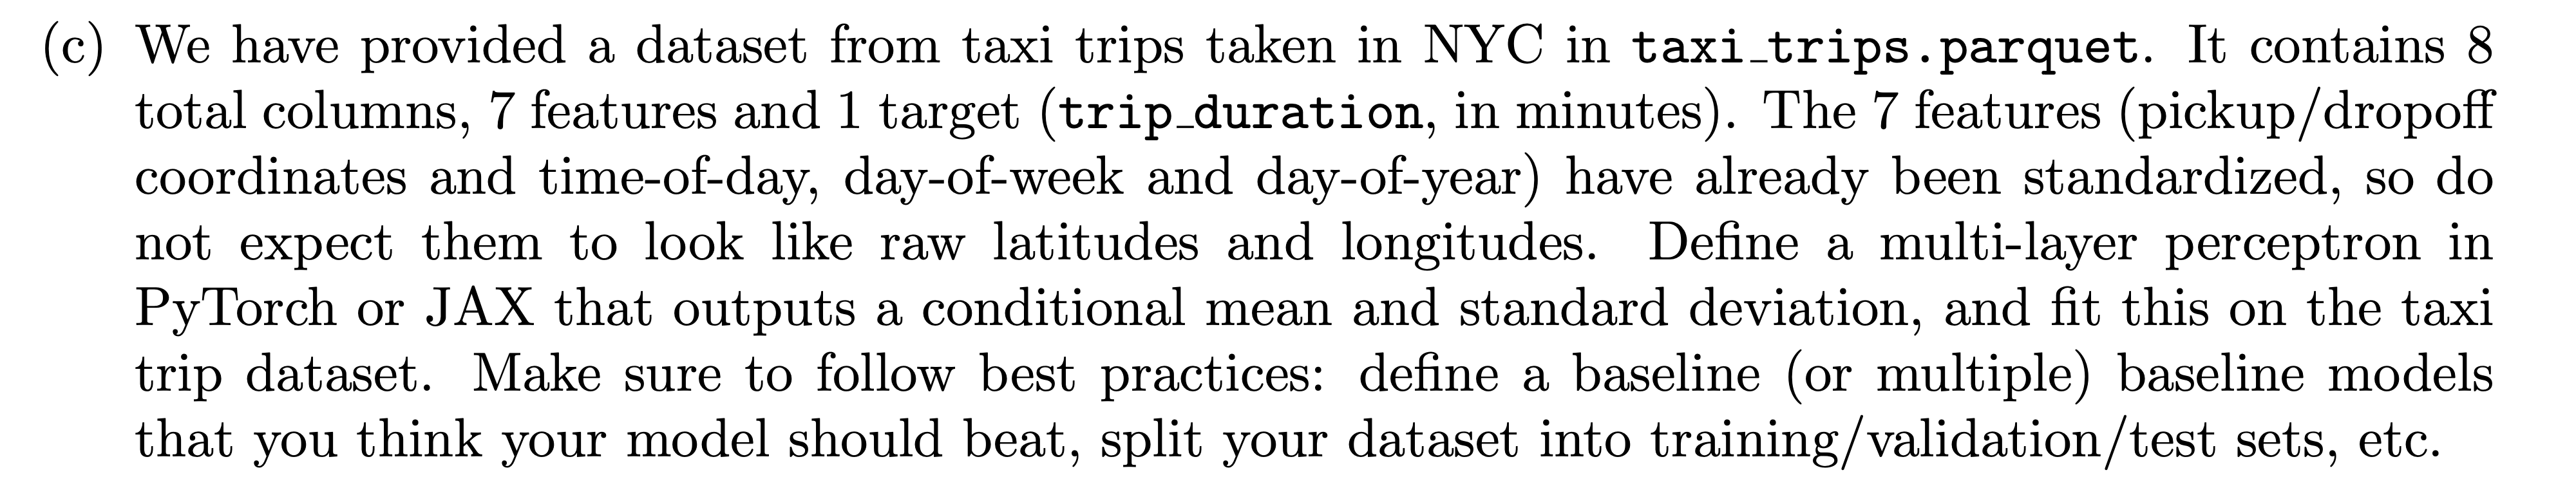

In [1]:
import sys, pandas, pyarrow
print(sys.executable)
print(pandas.__version__, pandas.__file__)
print(pyarrow.__version__)

/Users/luissequeira/dev/UChicago/.venv312/bin/python
3.1.0 /Users/luissequeira/dev/UChicago/.venv312/lib/python3.12/site-packages/pandas/__init__.py
20.0.0


In [2]:
import pandas as pd

taxi_data = pd.read_parquet("data/taxi_trips.parquet")
taxi_data.head()

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,min_of_day,day_of_week,day_of_year
187173,0.270744,1.425051,0.466831,0.776192,7.965142,-0.942057,-1.047619,1.180855
179655,0.085681,0.306079,-0.226274,0.124111,10.680277,0.778703,-1.047619,-0.311290
120048,-0.555533,-0.934806,-0.022489,-0.548561,5.716184,-1.183016,-1.047619,1.316504
62587,0.069718,0.035804,0.258900,0.317284,4.266709,-0.908008,0.481657,0.018144
212063,-0.234482,0.074616,0.115836,0.258310,11.629685,1.066806,-0.537860,0.521985


In [3]:
taxi_data = taxi_data.reset_index(drop=True)

In [4]:
taxi_data.head()

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,min_of_day,day_of_week,day_of_year
0,0.270744,1.425051,0.466831,0.776192,7.965142,-0.942057,-1.047619,1.180855
1,0.085681,0.306079,-0.226274,0.124111,10.680277,0.778703,-1.047619,-0.311290
2,-0.555533,-0.934806,-0.022489,-0.548561,5.716184,-1.183016,-1.047619,1.316504
3,0.069718,0.035804,0.258900,0.317284,4.266709,-0.908008,0.481657,0.018144
4,-0.234482,0.074616,0.115836,0.258310,11.629685,1.066806,-0.537860,0.521985


In [5]:
print(taxi_data.shape)
print(taxi_data["trip_duration"].describe())


(523554, 8)
count    523554.000000
mean         10.413050
std           7.754068
min           0.033386
25%           4.749882
50%           8.631456
75%          13.928152
max         227.942612
Name: trip_duration, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 98
np.random.seed(SEED)
torch.manual_seed(SEED)
device = "cpu"

feature_cols = [c for c in taxi_data.columns if c != "trip_duration"]

X = taxi_data[feature_cols].to_numpy(dtype=np.float32)
y = taxi_data["trip_duration"].to_numpy(dtype=np.float32)

# Split train / val / test (70 / 15 / 15)
n = len(X)
perm = np.random.RandomState(SEED).permutation(n)
n_train, n_val = int(0.70 * n), int(0.15 * n)
idx_train = perm[:n_train]  # from 0 to index n_train-1
idx_val = perm[n_train:n_train + n_val]  # from index n_train to n_train + n_val -1
idx_test = perm[n_train + n_val:]  # from index n_train + n_val onwards

X_train, y_train = X[idx_train], y[idx_train]
X_val, y_val = X[idx_val], y[idx_val]
X_test, y_test = X[idx_test], y[idx_test]
print(len(X_train), len(X_val), len(X_test))  # validating train, validation and test sizes


# Metrics to calculate
def loss_b(y, mu, sigma):
    """loss from question 1b): sum_i [ log f_sigma(x_i) + (y_i - f_mu(x_i))^2 / (2 f_sigma(x_i)^2) ]"""
    y, mu, sigma = map(np.asarray, (y, mu, sigma))
    return np.sum(np.log(sigma) + (y - mu) ** 2 / (2 * sigma ** 2))


def report(name, y, mu, sigma):
    mu = np.broadcast_to(mu, y.shape)
    sigma = np.broadcast_to(sigma, y.shape)
    total = loss_b(y, mu, sigma)
    out = {
        "model": name,
        "loss_b (sum)": total,
        "loss_b (mean)": total / len(y),  # per-sample, comparable across splits
        "RMSE": np.sqrt(np.mean((y - mu) ** 2)),
        "MAE": np.mean(np.abs(y - mu))
    }
    return out


# Baseline 1: mu and sigma as constant values
mu0, sigma0 = y_train.mean(), y_train.std()
res_val = [report("const (mean, std)", y_val, mu0, sigma0)]

# Baseline 2: regression OLS with sigma as std from residuals
A_train = np.c_[np.ones(len(X_train)), X_train]
beta, *_ = np.linalg.lstsq(A_train, y_train, rcond=None)  # to obtain the betas


def pred(X_):
    with np.errstate(all="ignore"):
        out = np.c_[np.ones(len(X_)), X_] @ beta  # I multiply my data by the betas
    assert np.isfinite(out).all()
    return out


sigma_lin = (y_train - pred(X_train)).std()  # I see the residuals and obtain the standard deviation
res_val.append(report("linear + sigma const", y_val, pred(X_val), sigma_lin))  # validation performance

366487 78533 78534


epoch   0 | train 1.9560 | val 1.9645
epoch  10 | train 1.6813 | val 1.7412
epoch  20 | train 1.6555 | val 1.7422
epoch  30 | train 1.6473 | val 1.7364
epoch  40 | train 1.5867 | val 1.7346
epoch  50 | train 1.5796 | val 1.7382
Early stopping at epoch 56 (best val 1.7149)


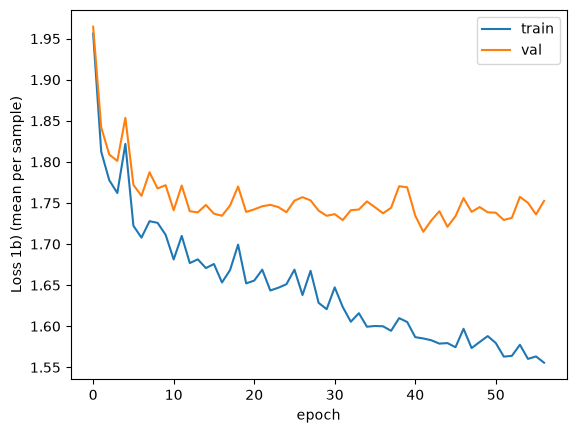

VALIDATION
                model  loss_b (sum)  loss_b (mean)   RMSE    MAE
    const (mean, std)   201131.7812         2.5611 7.8527 5.7103
 linear + sigma const   198689.7872         2.5300 7.6131 5.5869
MLP (mu(x), sigma(x))   134676.9062         1.7149 3.9150 2.4086

TEST
                model  loss_b (sum)  loss_b (mean)   RMSE    MAE
    const (mean, std)   200274.5156         2.5502 7.7690 5.6930
 linear + sigma const   198216.3556         2.5240 7.5679 5.5785
MLP (mu(x), sigma(x))   140281.2812         1.7862 3.8289 2.3828
sigma(x) on test: min 0.910 | median 3.224 | max 233.312


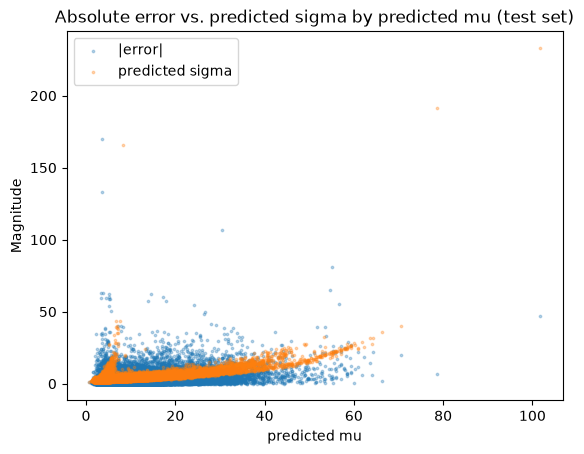

In [7]:
# Model: multi-layer-perceptron it returns mu + sigma
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

class GaussianMLP(nn.Module):
    def __init__(self, in_dim, widths=(32, 64, 128, 64, 32)):
        super().__init__()
        layers, d = [], in_dim
        for w in widths:
            layers += [nn.Linear(d, w), nn.ReLU()]
            d = w
        self.body = nn.Sequential(*layers) 
        self.head = nn.Linear(d, 2)

    def forward(self, x):
        g = self.head(self.body(x))
        f_mu = g[:, 0]  # identity link, as in 1a)
        f_sigma = torch.exp(g[:, 1])  # exponential link from 1a): ensures f_sigma(x) > 0 for all x
        return f_mu, f_sigma


def nll_loss(y, f_mu, f_sigma, reduction="mean"):
    """loss from question 1b): sum_i [ log f_sigma(x_i) + (y_i - f_mu(x_i))^2 / (2 f_sigma(x_i)^2) ]
    reduction="mean" divides by n so the step size does not depend on batch/split size."""
    per_sample = torch.log(f_sigma) + (y - f_mu) ** 2 / (2 * f_sigma ** 2)
    return per_sample.sum() if reduction == "sum" else per_sample.mean()


to_t = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
Xtr, ytr = to_t(X_train), to_t(y_train)
Xva, yva = to_t(X_val), to_t(y_val)
Xte, yte = to_t(X_test), to_t(y_test)  # transforming everything to tensors

model = GaussianMLP(X_train.shape[1]).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
batch_size, max_epochs, patience = 512, 200, 15

best_val, best_state, bad = np.inf, None, 0
hist = {"train": [], "val": []}

for epoch in range(max_epochs):
    model.train()
    perm_t = torch.randperm(len(Xtr), device=device)
    for i in range(0, len(Xtr), batch_size):
        b = perm_t[i:i + batch_size]
        f_mu, f_sigma = model(Xtr[b])
        loss = nll_loss(ytr[b], f_mu, f_sigma)
        opt.zero_grad()
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        tr = nll_loss(ytr, *model(Xtr)).item()
        va = nll_loss(yva, *model(Xva)).item()
    hist["train"].append(tr)
    hist["val"].append(va)

    if va < best_val - 1e-4:
        best_val, bad = va, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= patience:
            print(f"Early stopping at epoch {epoch} (best val {best_val:.4f})")
            break
    if epoch % 10 == 0:
        print(f"epoch {epoch:3d} | train {tr:.4f} | val {va:.4f}")

model.load_state_dict(best_state)

# Learning curves (per-sample mean loss, so train and val are on the same scale)
plt.plot(hist["train"], label="train")
plt.plot(hist["val"], label="val")
plt.xlabel("epoch")
plt.ylabel("Loss 1b) (mean per sample)")
plt.legend()
plt.show()


# Evaluation on validation and test (the test set is used ONLY once)
def predict(model, X_):
    model.eval()
    with torch.no_grad():
        f_mu, f_sigma = model(X_)
    return f_mu.cpu().numpy(), f_sigma.cpu().numpy()


mu_va, sig_va = predict(model, Xva)
res_val.append(report("MLP (mu(x), sigma(x))", y_val, mu_va, sig_va))
print("VALIDATION")
print(pd.DataFrame(res_val).round(4).to_string(index=False))

res_test = [
    report("const (mean, std)", y_test, mu0, sigma0),
    report("linear + sigma const", y_test, pred(X_test), sigma_lin),
    report("MLP (mu(x), sigma(x))", y_test, *predict(model, Xte)),
]
print("\nTEST")
print(pd.DataFrame(res_test).round(4).to_string(index=False))

mu_te, sig_te = predict(model, Xte)
print("sigma(x) on test: min %.3f | median %.3f | max %.3f"
      % (sig_te.min(), np.median(sig_te), sig_te.max()))

plt.scatter(mu_te, np.abs(y_test - mu_te), s=3, alpha=0.3, label="|error|")
plt.scatter(mu_te, sig_te, s=3, alpha=0.3, label="predicted sigma")
plt.xlabel("predicted mu")
plt.title("Absolute error vs. predicted sigma by predicted mu (test set)")
plt.ylabel("Magnitude")
plt.legend()
plt.show()

The MLP outperforms the two baselines I included (a constant mean + std, and a linear model with a constant σ) on the test set across all metrics. Its mean loss from 1b) is 1.817, against 2.550 for the constant baseline and 2.524 for the linear one. RMSE drops from 7.57 (linear) to 3.82 minutes and MAE from 5.58 to 2.41 minutes, so the MLP roughly halves the error of the best baseline.

The linear model barely improves on the constant baseline, which suggests that trip duration depends non-linearly on the features (for example, on the distance between the pickup and dropoff coordinates). Because the MLP also predicts a σ(x) for each trip (median 3.16, ranging from 0.78 to 32 minutes), it can be confident on short, predictable trips and widen its uncertainty on the harder ones. That's why its loss improves much more than a constant σ allows.

The test loss (1.817) is slightly higher than the validation loss (1.712). The difference comes mostly from a few very long trips (up to 228 minutes) that the model doesn't expect. I used the test set only once, for this final evaluation, after choosing the model with early stopping on validation.

### (d) Probability that a trip takes less than 45 minutes

Under the model $Y \mid X = x \sim \mathcal{N}(f_\mu(x), f_\sigma(x)^2)$, the probability that a trip takes less than 45 minutes is the Gaussian CDF evaluated at 45:

$$
P(Y < 45 \mid X = x) = \Phi\left(\frac{45 - f_\mu(x)}{f_\sigma(x)}\right)
$$

where $\Phi$ is the CDF of the standard normal. For each trip we plug the predicted $f_\mu(x)$ and $f_\sigma(x)$ from the MLP into this formula.

### (e) Evaluating the predicted probabilities on the test set

We compute $P(Y < 45 \mid x)$ for every test trip and compare it with the true outcome $\mathbb{1}[y < 45]$ using two proper scoring rules (Brier score and log-loss), plus the classification accuracy obtained by thresholding the probability at 0.5.

In [8]:
# (e) Estimate P(trip < 45 min) on the held-out test set and evaluate it
from scipy.stats import norm
from sklearn.metrics import brier_score_loss, log_loss, accuracy_score

THRESHOLD = 45
z_test = (y_test < THRESHOLD).astype(int)  # true label: 1 if the trip took < 45 min
print(f"Share of test trips < {THRESHOLD} min: {z_test.mean():.4f}")


def prob_below(mu, sigma, t=THRESHOLD):
    """P(Y < t | x) = Phi((t - mu) / sigma) under the Gaussian model"""
    mu = np.broadcast_to(mu, y_test.shape)
    sigma = np.broadcast_to(sigma, y_test.shape)
    return norm.cdf((t - mu) / sigma)


def report_prob(name, p, z=z_test):
    p = np.clip(p, 1e-12, 1 - 1e-12)  # avoid log(0) in the log-loss
    return {
        "model": name,
        "Brier": brier_score_loss(z, p),
        "log-loss": log_loss(z, p, labels=[0, 1]),
        "accuracy (p > 0.5)": accuracy_score(z, (p > 0.5).astype(int)),
    }


# Baseline for the probabilities: same probability for every trip = share of train trips < 45 min
p_train_rate = np.full(y_test.shape, (y_train < THRESHOLD).mean())

res_prob = [
    report_prob("train rate (constant p)", p_train_rate),
    report_prob("const (mean, std)", prob_below(mu0, sigma0)),
    report_prob("linear + sigma const", prob_below(pred(X_test), sigma_lin)),
    report_prob("MLP (mu(x), sigma(x))", prob_below(mu_te, sig_te)),
]
print(pd.DataFrame(res_prob).round(4).to_string(index=False))

Share of test trips < 45 min: 0.9954
                  model  Brier  log-loss  accuracy (p > 0.5)
train rate (constant p) 0.0046    0.0293              0.9954
      const (mean, std) 0.0046    0.0572              0.9954
   linear + sigma const 0.0046    0.0481              0.9954
  MLP (mu(x), sigma(x)) 0.0031    0.0195              0.9965


In [9]:
sig_te

array([3.1110601, 3.0669317, 3.1648474, ..., 4.263617 , 3.4882998,
       2.9476256], dtype=float32)

The MLP is able to obtain the lowest Brier score, log-loss and the higher accuracy in the test set.

# 2  
For this problem, you will explore different methods for encoding categorical random variables. We have
provided a dataset retail.csv, which contains data on retail transactions. We’ve cleaned up the data a
bit so you only have two features: StockCode and CustomerID, both of which are categorical. (You may
need to convert them to categorical data types in your code for the encoding methods to work properly.)
The target is Quantity, which is a positive integer. Note that Quantity is very heavy-tailed (most values are small, but a few are enormous), so think about what loss function and/or target transformation is appropriate.

a) Start by exploring the cardinality of the two features. How many unique values are there for each
feature? What does this suggest about how you might encode them? Is one-hot encoding feasible?
To prepare for the next steps, split the data into training, validation, and test sets. The validation
set will allow you to use early stopping during training for the neural network models.

In [10]:
retail = pd.read_csv("data/retail.csv")
retail["CustomerID"]= retail["CustomerID"].astype("category")
retail["StockCode"]= retail["StockCode"].astype("category")

In [11]:
retail.nunique()

Quantity       302
StockCode     3665
CustomerID    4339
dtype: int64

Number of unique values per feature:
- StockCode     3665
- CustomerID    4339

To encode the data using one-hot encoding would be extremely complicated from a computational point of view. Another option is to replace each category with summary statistics such as its frequency, computed on the training set to train the model.



In [12]:
# 2a) Train / validation / test split (70 / 15 / 15)
SEED = 98

retail = pd.read_csv("data/retail.csv")

# Both features are categorical; CustomerID is read as float (e.g. 17850.0), so convert it first
retail["StockCode"] = retail["StockCode"].astype(str).astype("category")
retail["CustomerID"] = retail["CustomerID"].astype(int).astype(str).astype("category")

n = len(retail)
perm = np.random.RandomState(SEED).permutation(n)
n_train, n_val = int(0.70 * n), int(0.15 * n)

train = retail.iloc[perm[:n_train]].reset_index(drop=True)
val = retail.iloc[perm[n_train:n_train + n_val]].reset_index(drop=True)
test = retail.iloc[perm[n_train + n_val:]].reset_index(drop=True)
print(len(train), len(val), len(test))


278546 59688 59690


b) Try target encoding. For each unique value of the feature, replace it with the mean of the target for that value (from the training set). You can use TargetEncoder from the category encoders package. Using an appropriate loss function, fit a model of your choice to the data using the target-encoded features. Evaluate the model on the test set.

Since the data has some outliers, I propose using the Mean squared logarithmic error as my loss function.

In [13]:
import category_encoders as ce
print(ce.__version__)

2.11.2


In [18]:
import category_encoders as ce

torch.manual_seed(SEED)
cols = ["StockCode", "CustomerID"]

# 1. Targets in log space (loss = MSE on log1p(y) == MSLE)
ytr = np.log1p(train["Quantity"].values) #This transformation reduces the impact of the outliers
yva = np.log1p(val["Quantity"].values)
yte = np.log1p(test["Quantity"].values)

# 2. Target encoding: each category -> (smoothed) mean of the target, fitted on TRAIN only
enc = ce.TargetEncoder(cols=cols, smoothing=10)
Xtr = enc.fit_transform(train[cols].astype(str), ytr)
Xva = enc.transform(val[cols].astype(str))
Xte = enc.transform(test[cols].astype(str))

# 3. Tensors + standardize with train statistics
to_t = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
Xtr_t, Xva_t, Xte_t = to_t(Xtr), to_t(Xva), to_t(Xte)
ytr_t, yva_t, yte_t = to_t(ytr), to_t(yva), to_t(yte)
m, s = Xtr_t.mean(0), Xtr_t.std(0) + 1e-8
Xtr_t, Xva_t, Xte_t = [(x - m) / s for x in (Xtr_t, Xva_t, Xte_t)]

# 4. Model: small MLP on the 2 encoded features
model = nn.Sequential(
    nn.Linear(2, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 1),
)
opt = torch.optim.SGD(model.parameters(), lr=.001)
loss_fn = nn.MSELoss()
fwd = lambda x: model(x).squeeze(-1)

# 5. Train with early stopping on validation
batch_size, max_epochs, patience = 512, 200, 15
best_val, best_state, bad = np.inf, None, 0
hist = {"train": [], "val": []}

for epoch in range(max_epochs):
    model.train()
    perm = torch.randperm(len(Xtr_t))
    for i in range(0, len(Xtr_t), batch_size):
        b = perm[i:i + batch_size]
        loss = loss_fn(fwd(Xtr_t[b]), ytr_t[b])
        opt.zero_grad(); loss.backward(); opt.step()

    model.eval()
    with torch.no_grad():
        tr = loss_fn(fwd(Xtr_t), ytr_t).item()
        va = loss_fn(fwd(Xva_t), yva_t).item()
    hist["train"].append(tr); hist["val"].append(va)

    if va < best_val - 1e-5:
        best_val, bad = va, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= patience:
            print(f"Early stopping at epoch {epoch} (best val MSLE {best_val:.4f})")
            break

model.load_state_dict(best_state)

# 6. Evaluate on test (use the test set once)
model.eval()
with torch.no_grad():
    pred_log = fwd(Xte_t).numpy()
pred_qty = np.clip(np.expm1(pred_log), 1, None)       # forecasts in units

test_msle = np.mean((yte - pred_log) ** 2)
base_msle = np.mean((yte - ytr.mean()) ** 2)           # baseline: constant prediction
test_mae  = np.mean(np.abs(test["Quantity"].values - pred_qty))
print(f"Test MSLE: {test_msle:.4f} | baseline MSLE: {base_msle:.4f} | MAE: {test_mae:.2f}")

Test MSLE: 0.3483 | baseline MSLE: 1.0120 | MAE: 7.04


In [17]:
Xtr_t

tensor([[-0.3221, -0.4717],
        [ 0.1946,  0.4366],
        [ 0.0160,  0.6553],
        ...,
        [-0.3730,  0.6363],
        [-0.0021, -1.2669],
        [-0.5870, -1.0995]])

 2c) Try a neural network model with an embedding layer for each of the two features. Choose a reasonable embedding dimension. Fit this model to the data. Evaluate the model on the test set. How does it compare to the target encoding model?

In [26]:
train.head()

,Quantity,StockCode,CustomerID
0,6,23329,15752
1,18,22731,14125
2,12,84380,16092
3,2,22767,18160
4,2,82484,14759


Early stopping at epoch 70 (best val MSLE 0.2917)


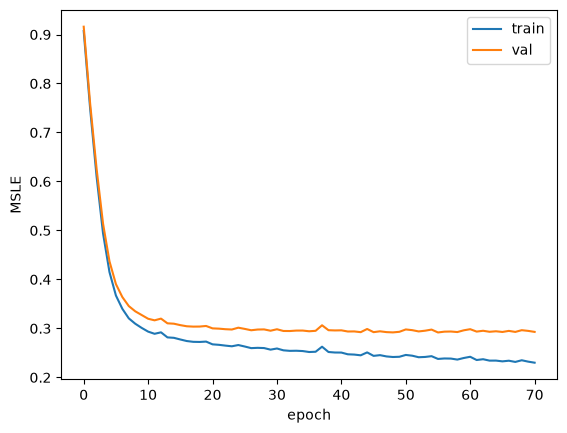

Embeddings | test MSLE: 0.2883 | MAE: 6.27


In [19]:
# 2c) Neural network with one embedding layer per categorical feature
torch.manual_seed(SEED)
cols = ["StockCode", "CustomerID"]
EMB_DIM = 8  # Dimension of the embedding vector

# 1. Vocabulary from TRAIN only: category -> integer index (1, 2, ...);
#    index 0 is reserved for categories never seen in training
vocab = {c: {cat: i + 1 for i, cat in enumerate(train[c].unique())} for c in cols}

def to_idx(df):
    return torch.tensor(
        np.stack([df[c].astype(str).map(vocab[c]).fillna(0).astype(int).values for c in cols], axis=1),
        dtype=torch.long)

Itr_emb, Iva_emb, Ite_emb = to_idx(train), to_idx(val), to_idx(test)
ytr_emb = torch.tensor(np.log1p(train["Quantity"].values), dtype=torch.float32)  # MSLE: MSE on log1p
yva_emb = torch.tensor(np.log1p(val["Quantity"].values), dtype=torch.float32)
yte_emb = torch.tensor(np.log1p(test["Quantity"].values), dtype=torch.float32)


# 2. Model: embedding per feature -> concatenate -> MLP -> 1 output (log1p of quantity)
class EmbeddingNet(nn.Module):
    def __init__(self, n_stock, n_cust, dim=EMB_DIM):
        super().__init__()
        # padding_idx=0: the "unknown" row stays at zeros and is never updated
        self.emb_stock = nn.Embedding(n_stock + 1, dim, padding_idx=0)
        self.emb_cust = nn.Embedding(n_cust + 1, dim, padding_idx=0)
        self.mlp = nn.Sequential(
            nn.Linear(2 * dim, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, idx):
        e = torch.cat([self.emb_stock(idx[:, 0]), self.emb_cust(idx[:, 1])], dim=1)
        return self.mlp(e).squeeze(-1)


model_emb = EmbeddingNet(len(vocab["StockCode"]), len(vocab["CustomerID"]))
opt_emb = torch.optim.Adam(model_emb.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# 3. Train with early stopping on validation
batch_size, max_epochs, patience = 1024, 200, 15
best_val, best_state, bad = np.inf, None, 0
hist_emb = {"train": [], "val": []}

for epoch in range(max_epochs):
    model_emb.train()
    perm_t = torch.randperm(len(Itr_emb))
    for i in range(0, len(Itr_emb), batch_size):
        b = perm_t[i:i + batch_size]
        loss = loss_fn(model_emb(Itr_emb[b]), ytr_emb[b])
        opt_emb.zero_grad(); loss.backward(); opt_emb.step()

    model_emb.eval()
    with torch.no_grad():
        tr = loss_fn(model_emb(Itr_emb), ytr_emb).item()
        va = loss_fn(model_emb(Iva_emb), yva_emb).item()
    hist_emb["train"].append(tr); hist_emb["val"].append(va)

    if va < best_val - 1e-5:
        best_val, bad = va, 0
        best_state = {k: v.clone() for k, v in model_emb.state_dict().items()}
    else:
        bad += 1
        if bad >= patience:
            print(f"Early stopping at epoch {epoch} (best val MSLE {best_val:.4f})")
            break

model_emb.load_state_dict(best_state)

plt.plot(hist_emb["train"], label="train")
plt.plot(hist_emb["val"], label="val")
plt.xlabel("epoch"); plt.ylabel("MSLE"); plt.legend(); plt.show()

# 4. Evaluate on test (use the test set once)
with torch.no_grad():
    pred_log_emb = model_emb(Ite_emb).numpy()
pred_qty_emb = np.clip(np.expm1(pred_log_emb), 1, None)  # forecasts in units

test_msle_emb = np.mean((yte_emb.numpy() - pred_log_emb) ** 2)
test_mae_emb = np.mean(np.abs(test["Quantity"].values - pred_qty_emb))
print(f"Embeddings | test MSLE: {test_msle_emb:.4f} | MAE: {test_mae_emb:.2f}")


On the test set, the embedding model reaches an MSLE of 0.288 and an MAE of 6.27 units, compared with 0.348 and 7.04 for the target encoding model. Both models use the same split, target transformation (log1p), loss (MSLE).

 MLP architecture and early stopping. Embeddings reduce the test MSLE by about 17% and the MAE by about 11% relative to target encoding.

In [28]:
train

,Quantity,StockCode,CustomerID
0,6,23329,15752
1,18,22731,14125
2,12,84380,16092
3,2,22767,18160
4,2,82484,14759
...,...,...,...
278541,240,22952,14005
278542,6,22457,16180
278543,2,22557,13599
278544,2,21930,14723


In [29]:
retail

,Quantity,StockCode,CustomerID
0,6,85123A,17850
1,6,71053,17850
2,8,84406B,17850
3,6,84029G,17850
4,6,84029E,17850
...,...,...,...
397919,12,22613,12680
397920,6,22899,12680
397921,4,23254,12680
397922,4,23255,12680


In [25]:
len(vocab["StockCode"]) 

3606

(d) What if we combine the two? That is, use both the target encoded features and the embeddings as
input to the neural network. Fit this model to the data. Evaluate the model on the test set. How
does it compare to the other two models?

Early stopping at epoch 50 (best val MSLE 0.2900)


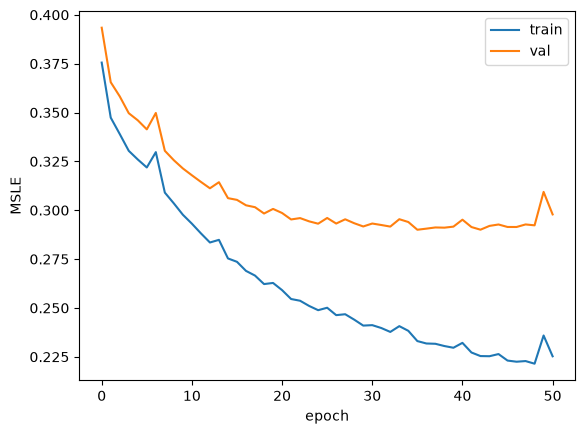

Combined | test MSLE: 0.2873 | MAE: 6.32
               model  test MSLE  test MAE
target encoding (2b)     0.3483    7.0379
     embeddings (2c)     0.2883    6.2721
       combined (2d)     0.2873    6.3236


In [ ]:
# 2d) Combine both: target-encoded features (from 2b) + embeddings (from 2c) as input to the MLP
torch.manual_seed(SEED)

# Reuses from 2b: Xtr_t, Xva_t, Xte_t  (2 standardized target-encoded features per row)
# Reuses from 2c: Itr_emb, Iva_emb, Ite_emb (category indices) and ytr_emb, yva_emb, yte_emb (log1p targets)

class CombinedNet(nn.Module):
    def __init__(self, n_stock, n_cust, dim=EMB_DIM, n_te=2):
        super().__init__()
        self.emb_stock = nn.Embedding(n_stock + 1, dim, padding_idx=0)
        self.emb_cust = nn.Embedding(n_cust + 1, dim, padding_idx=0)
        self.mlp = nn.Sequential(
            nn.Linear(2 * dim + n_te, 64), nn.ReLU(),  # 8 + 8 embedding numbers + 2 target-encoded
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, idx, x_te):
        e = torch.cat([self.emb_stock(idx[:, 0]), self.emb_cust(idx[:, 1]), x_te], dim=1)
        return self.mlp(e).squeeze(-1)

model_comb = CombinedNet(len(vocab["StockCode"]), len(vocab["CustomerID"]))
opt_comb = torch.optim.SGD(model_comb.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# Train with early stopping on validation (same settings as 2c)
batch_size, max_epochs, patience = 1024, 200, 15
best_val, best_state, bad = np.inf, None, 0
hist_comb = {"train": [], "val": []}

for epoch in range(max_epochs):
    model_comb.train()
    perm_t = torch.randperm(len(Itr_emb))
    for i in range(0, len(Itr_emb), batch_size):
        b = perm_t[i:i + batch_size]
        loss = loss_fn(model_comb(Itr_emb[b], Xtr_t[b]), ytr_emb[b])
        opt_comb.zero_grad(); loss.backward(); opt_comb.step()

    model_comb.eval()
    with torch.no_grad():
        tr = loss_fn(model_comb(Itr_emb, Xtr_t), ytr_emb).item()
        va = loss_fn(model_comb(Iva_emb, Xva_t), yva_emb).item()
    hist_comb["train"].append(tr); hist_comb["val"].append(va)

    if va < best_val - 1e-5:
        best_val, bad = va, 0
        best_state = {k: v.clone() for k, v in model_comb.state_dict().items()}
    else:
        bad += 1
        if bad >= patience:
            print(f"Early stopping at epoch {epoch} (best val MSLE {best_val:.4f})")
            break

model_comb.load_state_dict(best_state)

plt.plot(hist_comb["train"], label="train")
plt.plot(hist_comb["val"], label="val")
plt.xlabel("epoch"); plt.ylabel("MSLE"); plt.legend(); plt.show()

# Evaluate on test (use the test set once)
with torch.no_grad():
    pred_log_comb = model_comb(Ite_emb, Xte_t).numpy()
pred_qty_comb = np.clip(np.expm1(pred_log_comb), 1, None)  # forecasts in units

test_msle_comb = np.mean((yte_emb.numpy() - pred_log_comb) ** 2)
test_mae_comb = np.mean(np.abs(test["Quantity"].values - pred_qty_comb))
print(f"Combined | test MSLE: {test_msle_comb:.4f} | MAE: {test_mae_comb:.2f}")

# Comparison of the three models on the test set
print(pd.DataFrame({
    "model": ["target encoding (2b)", "embeddings (2c)", "combined (2d)"],
    "test MSLE": [test_msle, test_msle_emb, test_msle_comb],
    "test MAE": [test_mae, test_mae_emb, test_mae_comb],
}).round(4).to_string(index=False))


The combined model shows that adding the target encoding to the embeddings does not improve the model's performance in reality since it drops the MSLE but increases the MAE, but those changes are very small. 

This makes sense because target encoding, summarizes each category with a single fixed number, its average log-quantity. In this case, the model cannot learn how specific customers interact with specific types of products, so it adds little information to improve the actual model.

2e) Try to give some intuition for your results. What is the embedding layer doing? Why might it be
useful in this context? Evaluate your findings on the test set

An embedding layer is a learned lookup table: each StockCode and each CustomerID gets its own vector of 8 numbers, which are adjusted during training to minimize the loss. Mathematically, it compresses 3,665 products and 4,339 customers into 8 dimensions each. Products that are bought in similar quantities, or by similar customers, end up with similar vectors, so the model can share information between related categories. This is useful here because the features have very high cardinality and many categories have few observations.



Evaluating the test set, it is possible to see that the embeddings provide great improvements to the model's performance and that the target encoding doesn't really improve the model's performance when it is I added to the embeddings.

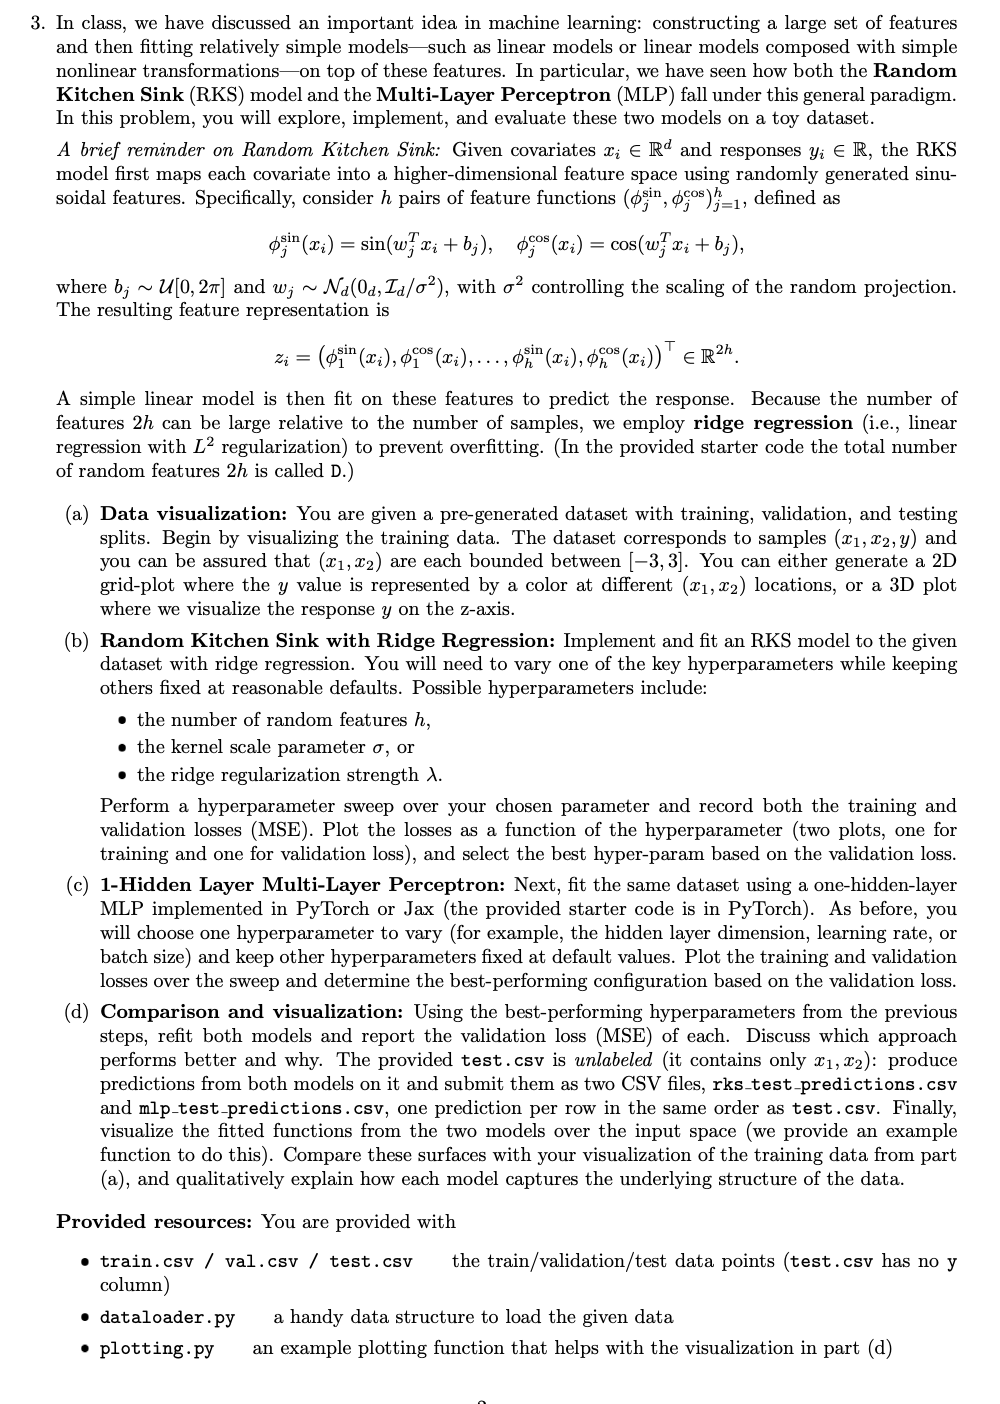

(600, 3)
         x1        x2         y
0  1.178815 -1.283164  1.752019
1 -1.638891  0.307889 -0.682641
2  1.316814 -0.461361  1.091145
3  2.884585  1.108978  0.918561
4 -0.114409 -0.647295 -0.187220


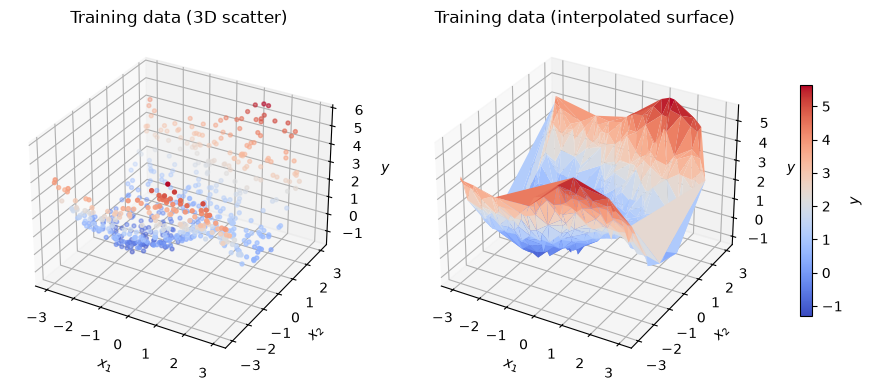

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# 3a) Visualize the training data in 3D: (x1, x2) on the floor, y on the z-axis
train = pd.read_csv("data/train.csv")  
print(train.shape)
print(train.head())

fig = plt.figure(figsize=(12, 5))

# Left: 3D scatter, one point per training sample, colored by y
ax = fig.add_subplot(1, 2, 1, projection="3d")
sc = ax.scatter(train["x1"], train["x2"], train["y"], c=train["y"], cmap="coolwarm", s=8)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$y$")
ax.set_title("Training data (3D scatter)")
ax.view_init(elev=30, azim=-60)

# Right: surface interpolated between the points, which makes the shape easier to see
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_trisurf(train["x1"], train["x2"], train["y"], cmap="coolwarm", linewidth=0, antialiased=True)
ax2.set_xlabel("$x_1$"); ax2.set_ylabel("$x_2$"); ax2.set_zlabel("$y$")
ax2.set_title("Training data (interpolated surface)")
ax2.view_init(elev=30, azim=-60)

fig.colorbar(sc, ax=[ax, ax2], shrink=0.6, label="$y$")
plt.show()


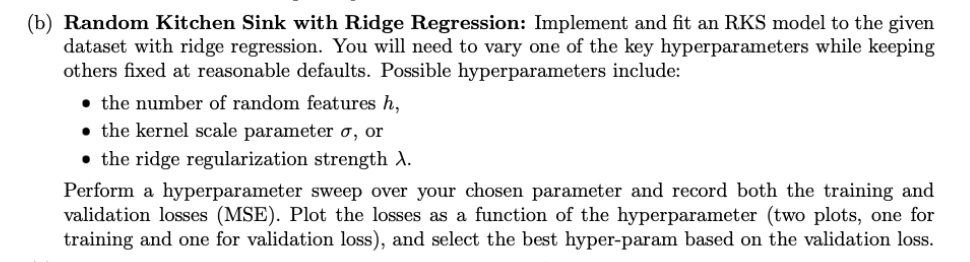

3b)

/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:37: RuntimeWarning: divide by zero encountered in matmul
  proj = X @ self.Weights
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:37: RuntimeWarning: overflow encountered in matmul
  proj = X @ self.Weights
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:37: RuntimeWarning: invalid value encountered in matmul
  proj = X @ self.Weights
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:63: RuntimeWarning: divide by zero encountered in matmul
  return phi @ self.coef_  # shape (n,)
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:63: RuntimeWarning: overflow encountered in matmul
  return phi @ self.coef_  # shape (n,)
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:63: RuntimeWarning: invalid value encountered in matmul
  return phi @ self.coef_  # shape (n,)
/var/f

Best D = 32, validation MSE = 0.03622


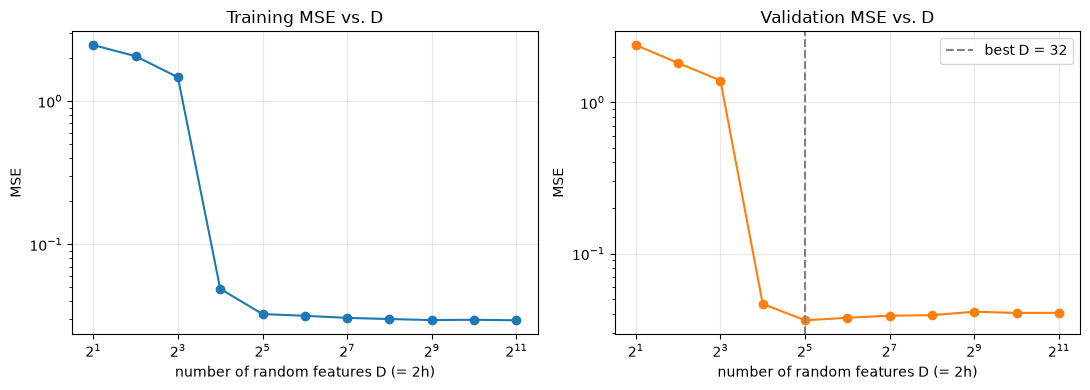

In [11]:
import numpy as np
from typing import List, Tuple

import torch
import torch.nn as nn


class RandomKitchenSinks:
    """
    Random Kitchen Sinks featurization with ridge regression.
    """
    def __init__(self, D: int = 1000, sigma: float = 1.0, ridge_lambda: float = 1e-3, seed = 98):
        """
        Potential hyper-parameters you can consider (feel free to add more):
            D: total number of random features (= 2h in the assignment text; if you use both sin and cos features, D should be an even number)
            sigma: scale parameter for the RBF kernel, used for initializing the weight parameters
            ridge_lambda: ridge regularization strength
        """
        #D is an even number
        self.D = D
        self.h = D//2
        self.sigma = sigma
        self.seed = seed
        self.ridge_lambda = ridge_lambda
        self.Weights = None
        self.coef_ = None

    def _features(self, X: np.ndarray) -> np.ndarray:
        """
        Convert the input data X into the random kitchen sinks features. You will likely need to use the parameters initialized in the __init__ method.
        The resulting features should be of shape (n, D or D[+1]), where the plus one is for the intercept term.
        """
        if self.Weights is None:
            #I will draw random weights once 
            rng = np.random.default_rng(self.seed)
            self.Weights = rng.normal(0,1.0/self.sigma, size=(X.shape[1], self.h))
        proj = X @ self.Weights
        phi = np.hstack([np.cos(proj), np.sin(proj)])/np.sqrt(self.h)
        return np.hstack([phi, np.ones((X.shape[0],1))]) #(n, D + 1)

    def fit(self, X: np.ndarray, y: np.ndarray):
        """
        Fit the ridge regression model to the (1) features computed from the input data X and (2) target values y.
        """
        self.Weights = None 
        phi = self._features(X)  # shape (n, D or D[+1])
        y = np.asarray(y, dtype= float)
        #Ridge closed form: Phi ^T Phi + lambda * I)w =Phi^T y
        #to redraw random features on every fit
        reg = self.ridge_lambda * np.eye(phi.shape[1])
        reg[-1,-1] = 0.0
        A = phi.T@phi + reg
        b = phi.T @ y
        self.coef_ = np.linalg.solve(A, b)
        return self


    def predict(self, X: np.ndarray) -> np.ndarray:
        """
        Predict the target values for the input data X.
        """
        phi = self._features(X)  # shape (n, D or D[+1])
        return phi @ self.coef_  # shape (n,)

def mse(ytrue, ypred):
    return float(np.mean((np.asarray(ytrue)- np.asarray(ypred))**2))

def sweep_rks_model(sweep_D: List[int], X_train: np.ndarray, y_train: np.ndarray, X_val: np.ndarray, y_val: np.ndarray) -> Tuple:
    """
    An example sweeping function that sweeps over the number of random features D, it then returns the best model in terms of validation MSE.
    Args:
        sweep_D: list of numbers of random features to sweep over
        X_train: training input data
        y_train: training target values
        X_val: validation input data
        y_val: validation target values
    Returns:
        a tuple (best_model, best_val_mse, best_D)
    """
    best_model = None
    best_val_mse = float('inf')
    best_D = None
    train_mses, val_mses = [], []
    for D in sweep_D:
        model = RandomKitchenSinks(D=D)
        model.fit(X_train, y_train)
        predicted_train = model.predict(X_train)
        predicted_val = model.predict(X_val)
        train_mse = mse(y_train,predicted_train)
        val_mse = mse(y_val,predicted_val)
        train_mses.append(train_mse)
        val_mses.append(val_mse)
        if val_mse < best_val_mse:
            best_model = model
            best_val_mse = val_mse
            best_D = D

    return best_model, best_val_mse, best_D, train_mses, val_mses
train = pd.read_csv("data/train.csv")
val = pd.read_csv("data/val.csv") 
X_train, y_train = train[["x1", "x2"]].values, train["y"].values
X_val, y_val = val[["x1", "x2"]].values, val["y"].values

# Sweep the number of random features; sigma and lambda stay fixed
sweep_D = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048]
best_model, best_val_mse, best_D, tr, va = sweep_rks_model(
    sweep_D, X_train, y_train, X_val, y_val
)
print(f"Best D = {best_D}, validation MSE = {best_val_mse:.5f}")

# Two separate plots: training loss and validation loss
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sweep_D, tr, "o-")
axes[0].set_title("Training MSE vs. D")
axes[1].plot(sweep_D, va, "o-", color="tab:orange")
axes[1].axvline(best_D, ls="--", color="gray", label=f"best D = {best_D}")
axes[1].set_title("Validation MSE vs. D")
axes[1].legend()
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("number of random features D (= 2h)")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


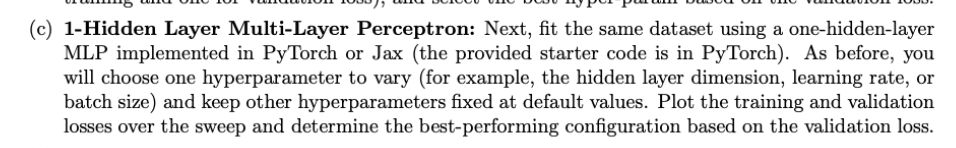

best V (hidden layer dimension) = 2048, validation MSE = 0.05015


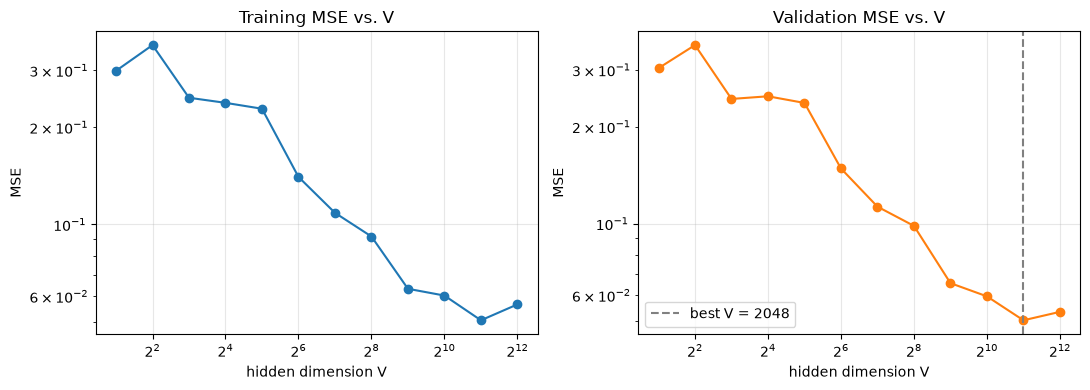

In [ ]:
"""
For 1-hidden-layer MLP (MLP)
"""
class MLP(nn.Module):
    """1-hidden-layer MLP for regression."""
    def __init__(self, d_in: int, d_hidden: int = 128, d_out: int = 1, lr: float = 1e-3, batch_size: int = 128, activation: str = "relu", device: str = "cpu"):
        """
        Potential hyper-parameters you can consider (feel free to add more):
            d_hidden: hidden dimension
            activation: activation function
            lr: learning rate
            batch_size: batch size
        """
        super().__init__()
        self.device = device
        self.layer_1 = nn.Linear(d_in, d_hidden)
        self.head = nn.Linear(d_hidden,d_out)
        self.body = nn.Sequential(self.layer_1, nn.ReLU())
        self.lr = lr
        self.batch_size = batch_size
        self.to(device)

    def fit(self, X: np.ndarray, y: np.ndarray, num_epochs: int = 1000):
        X = torch.from_numpy(X).float().to(self.device)
        y = torch.from_numpy(y).float().view(-1, 1).to(self.device)

        self.train()
        loss_fn = nn.MSELoss()
        optimizer = torch.optim.SGD(self.parameters(), lr=self.lr)

        n = len(X)
        for epoch in range(num_epochs):
            order = torch.randperm(n, device=self.device)
            for i in range(0, n, self.batch_size):
                b = order[i: i + self.batch_size]
                pred = self(X[b])
                loss = loss_fn(pred, y[b])
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                
        return self

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        x=self.head(self.body(X))
        return x

    def predict(self, X: np.ndarray) -> np.ndarray:
        self.eval()
        with torch.no_grad():
            X = torch.from_numpy(X).float().to(self.device)
            return self(X).squeeze(-1).cpu().numpy()
        

def mlp_sweep(sweep_values: List[float], X_train: np.ndarray, y_train: np.ndarray, X_val: np.ndarray, y_val: np.ndarray) -> Tuple:
    """
    See the example `sweep_rks_model` above for inspiration. Good luck!
    """
    best_model = None
    best_val_mse = float('inf')
    best_v = None
    train_mses, val_mses = [], []
    for v in sweep_values:
        model = MLP(X_train.shape[1],d_hidden=int(v))
        model.fit(X_train, y_train)
        predicted_train = model.predict(X_train)
        predicted_val = model.predict(X_val)
        train_mse = mse(y_train,predicted_train)
        val_mse = mse(y_val,predicted_val)
        train_mses.append(train_mse)
        val_mses.append(val_mse)
        if val_mse < best_val_mse:
            best_model = model
            best_val_mse = val_mse
            best_v = v
    return best_model, best_val_mse, best_v, train_mses, val_mses
    
train = pd.read_csv("data/train.csv")
val = pd.read_csv("data/val.csv") 
X_train, y_train = train[["x1", "x2"]].values, train["y"].values
X_val, y_val = val[["x1", "x2"]].values, val["y"].values

# Sweep the number of random features; sigma and lambda stay fixed
sweep_V = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096]
best_model_mlp, best_val_mse, best_V, tr, va = mlp_sweep(
    sweep_V, X_train, y_train, X_val, y_val
)
print(f"best V (hidden layer dimension) = {best_V}, validation MSE = {best_val_mse:.5f}")

# Two separate plots: training loss and validation loss
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sweep_V, tr, "o-")
axes[0].set_title("Training MSE vs. V")
axes[1].plot(sweep_V, va, "o-", color="tab:orange")
axes[1].axvline(best_V, ls="--", color="gray", label=f"best V = {best_V}")
axes[1].set_title("Validation MSE vs. V")
axes[1].legend()
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("hidden dimension V")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


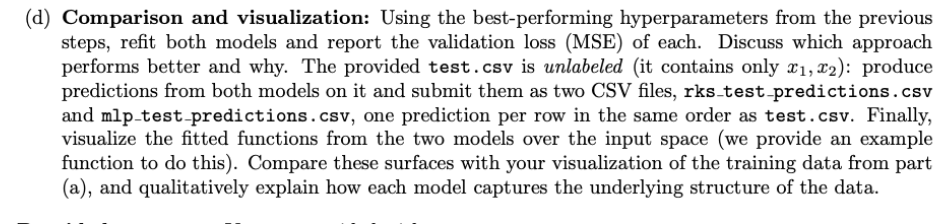

In [13]:
test

,x1,x2
0,1.557546,-2.864703
1,0.323211,-1.135584
2,1.993745,1.567926
3,-0.072969,-0.165863
4,-2.561063,-1.591982
...,...,...
195,-1.892067,-2.946150
196,-0.021042,-1.188311
197,-0.979265,1.999633
198,-2.463935,-2.455799


In [21]:
final_rks = RandomKitchenSinks(D=best_D)
final_rks.fit(X_train, y_train)
final_mlp = MLP(X_train.shape[1], d_hidden=int(best_V))
final_mlp.fit(X_train, y_train)

# 2) Val MSE for each one
rks_val_mse = mse(y_val, final_rks.predict(X_val))
mlp_val_mse = mse(y_val, final_mlp.predict(X_val))
print(f"RKS val MSE (D={best_D}) = {rks_val_mse:.5f}")
print(f"MLP val MSE (V={best_V}) = {mlp_val_mse:.5f}")

test = pd.read_csv("data/test.csv")
X_test = test[["x1", "x2"]].values

rks_out = test[["x1", "x2"]].copy()
rks_out["y"] = final_rks.predict(X_test)
rks_out.to_csv("data/rks_test_predictions.csv", index=False)

mlp_out = test[["x1", "x2"]].copy()
mlp_out["y"] = final_mlp.predict(X_test)
mlp_out.to_csv("data/mlp_test_predictions.csv", index=False)

/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:37: RuntimeWarning: divide by zero encountered in matmul
  proj = X @ self.Weights
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:37: RuntimeWarning: overflow encountered in matmul
  proj = X @ self.Weights
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:37: RuntimeWarning: invalid value encountered in matmul
  proj = X @ self.Weights
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:52: RuntimeWarning: divide by zero encountered in matmul
  A = phi.T@phi + reg
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:52: RuntimeWarning: overflow encountered in matmul
  A = phi.T@phi + reg
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:52: RuntimeWarning: invalid value encountered in matmul
  A = phi.T@phi + reg
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1

RKS val MSE (D=32) = 0.03622
MLP val MSE (V=2048) = 0.05264


/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:63: RuntimeWarning: divide by zero encountered in matmul
  return phi @ self.coef_  # shape (n,)
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:63: RuntimeWarning: overflow encountered in matmul
  return phi @ self.coef_  # shape (n,)
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:63: RuntimeWarning: invalid value encountered in matmul
  return phi @ self.coef_  # shape (n,)
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:37: RuntimeWarning: divide by zero encountered in matmul
  proj = X @ self.Weights
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:37: RuntimeWarning: overflow encountered in matmul
  proj = X @ self.Weights
/var/folders/8v/trqhvykn15q_10yjy54cfr540000gn/T/ipykernel_1532/3448592194.py:37: RuntimeWarning: invalid value encountered in matmul
  proj = X @ self.Weights
/var/f

In [22]:
train = pd.read_csv("data/rks_test_predictions.csv")  
train

,x1,x2,y
0,1.557546,-2.864703,5.032635
1,0.323211,-1.135584,0.967330
2,1.993745,1.567926,2.132742
3,-0.072969,-0.165863,-0.189510
4,-2.561063,-1.591982,0.678378
...,...,...,...
195,-1.892067,-2.946150,3.388514
196,-0.021042,-1.188311,0.680947
197,-0.979265,1.999633,1.204383
198,-2.463935,-2.455799,2.384275


(200, 3)
         x1        x2         y
0  1.557546 -2.864703  5.032635
1  0.323211 -1.135584  0.967330
2  1.993745  1.567926  2.132742
3 -0.072969 -0.165863 -0.189510
4 -2.561063 -1.591982  0.678378


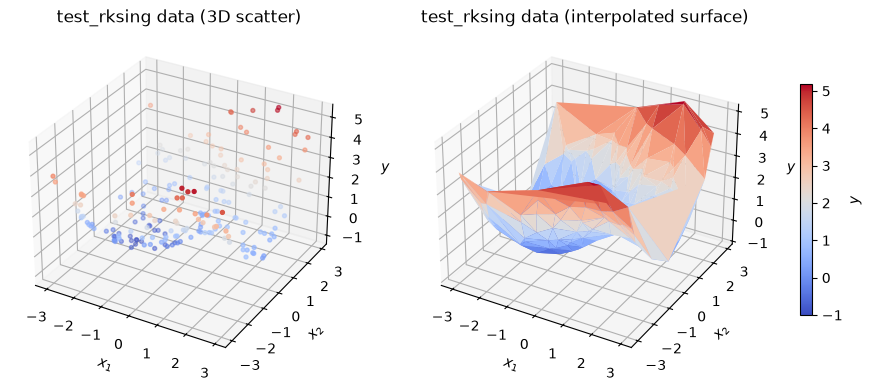

In [ ]:
#rks

import pandas as pd
import matplotlib.pyplot as plt

test_rks = pd.read_csv("data/rks_test_predictions.csv")  
print(test_rks.shape)
print(test_rks.head())

fig = plt.figure(figsize=(12, 5))

# Left: 3D scatter, one point per test_rksing sample, colored by y
ax = fig.add_subplot(1, 2, 1, projection="3d")
sc = ax.scatter(test_rks["x1"], test_rks["x2"], test_rks["y"], c=test_rks["y"], cmap="coolwarm", s=8)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$y$")
ax.set_title("test_rksing data (3D scatter)")
ax.view_init(elev=30, azim=-60)

# Right: surface interpolated between the points, which makes the shape easier to see
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_trisurf(test_rks["x1"], test_rks["x2"], test_rks["y"], cmap="coolwarm", linewidth=0, antialiased=True)
ax2.set_xlabel("$x_1$"); ax2.set_ylabel("$x_2$"); ax2.set_zlabel("$y$")
ax2.set_title("test_rksing data (interpolated surface)")
ax2.view_init(elev=30, azim=-60)

fig.colorbar(sc, ax=[ax, ax2], shrink=0.6, label="$y$")
plt.show()


(200, 3)
         x1        x2         y
0  1.557546 -2.864703  4.785394
1  0.323211 -1.135584  0.973458
2  1.993745  1.567926  2.078450
3 -0.072969 -0.165863 -0.158905
4 -2.561063 -1.591982  0.803068


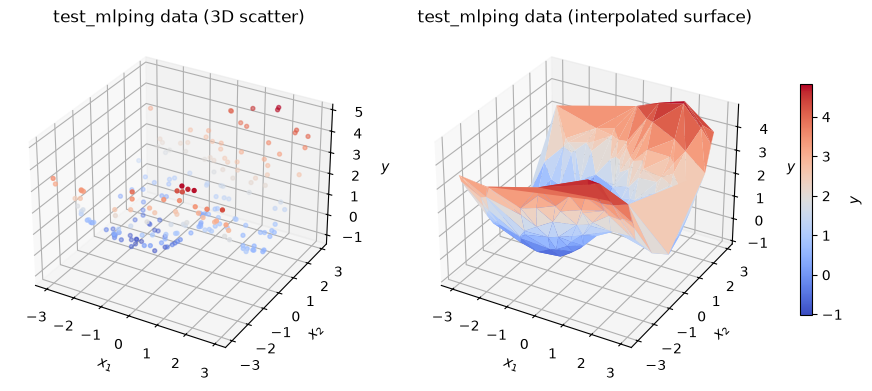

In [25]:
#MLP

import pandas as pd
import matplotlib.pyplot as plt

test_mlp = pd.read_csv("data/mlp_test_predictions.csv")  
print(test_mlp.shape)
print(test_mlp.head())

fig = plt.figure(figsize=(12, 5))

# Left: 3D scatter, one point per test_mlping sample, colored by y
ax = fig.add_subplot(1, 2, 1, projection="3d")
sc = ax.scatter(test_mlp["x1"], test_mlp["x2"], test_mlp["y"], c=test_mlp["y"], cmap="coolwarm", s=8)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$y$")
ax.set_title("test_mlping data (3D scatter)")
ax.view_init(elev=30, azim=-60)

# Right: surface interpolated between the points, which makes the shape easier to see
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_trisurf(test_mlp["x1"], test_mlp["x2"], test_mlp["y"], cmap="coolwarm", linewidth=0, antialiased=True)
ax2.set_xlabel("$x_1$"); ax2.set_ylabel("$x_2$"); ax2.set_zlabel("$y$")
ax2.set_title("test_mlping data (interpolated surface)")
ax2.view_init(elev=30, azim=-60)

fig.colorbar(sc, ax=[ax, ax2], shrink=0.6, label="$y$")
plt.show()
